# Timbre and rhythm together

The timbral model is weak (about 48%) but stable when the tempo changes, and the rhythm model is strong (about 82%) but collapses. Here the models get both: does the timbre make them more robust, or do they still take the tempo shortcut? The feature sets:

- Timbral and Rhythm (as before): the same as in the main notebooks, as a reference.
- Timbral + rhythm.
- Timbral + rhythm, tempo removed: timbre plus the rhythm set with the shifted cyclic tempogram.
- Timbral + scale transform.

Same classifiers, folds, tuning and 13 audio versions as the main notebooks.

## 1. Imports

In [1]:
from pathlib import Path
import platform
import time
import warnings

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.metrics import f1_score

import features as F
import evaluation as E

# harmless librosa 1.0 warning
warnings.filterwarnings('ignore', message='The `(hop_length|n_fft)` parameter is deprecated', category=FutureWarning)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180})
pd.set_option('display.max_columns', 30)
display(pd.Series({'python': platform.python_version(), 'numpy': np.__version__,
                   'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
                   'librosa': librosa.__version__}, name='version').to_frame())

,version
python,3.12.13
numpy,2.5.4
pandas,3.0.6
scikit-learn,1.9.1
librosa,1.0.0


## 2. Settings

The features of all 13 versions are saved in `all_versions_features.csv` the first time and reused after that, also by the other notebook in this folder.

In [2]:
DATASET_DIR = Path('../BallroomData')
FEATURES_PATH = Path('all_versions_features.csv')
MAIN_RESULTS_DIR = Path('../results')
RESULTS_DIR = Path('results') / 'timbre_plus_rhythm'

EXPECTED_CLIPS = 698
N_JOBS = 8                          # set to 1 if parallel runs give problems
MODEL_NAMES = list(E.MODELS)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)


def save(table, name, **options):
    table.to_csv(RESULTS_DIR / name, **options)


def save_figure(figure, name):
    figure.savefig(RESULTS_DIR / name, bbox_inches='tight')
    plt.show()

## 3. Clips and folds

Same clips and folds as the main notebooks. If their results are there, we check that every clip is in the same fold.

In [3]:
clips = E.find_clips(DATASET_DIR)
class_labels = np.sort(clips['label'].unique())
assert len(clips) == EXPECTED_CLIPS and len(class_labels) == 8, f'found {len(clips)} clips in {DATASET_DIR}'

folds = E.make_folds(clips)
clips = clips.merge(folds[['filename', 'group_id', 'fold']], on='filename', validate='one_to_one')

main_folds = MAIN_RESULTS_DIR / 'rhythm_random_forest' / 'rhythm' / 'out_of_fold_predictions.csv'
if main_folds.is_file():
    before = pd.read_csv(main_folds).set_index('filename')['fold']
    assert (clips.set_index('filename')['fold'] == before.loc[clips['filename']]).all()
    print('every clip is in the same test fold as in the main notebooks')
display(pd.crosstab(clips['fold'], clips['label'], margins=True))

every clip is in the same test fold as in the main notebooks


label,ChaChaCha,Jive,Quickstep,Rumba,Samba,Tango,VienneseWaltz,Waltz,All
fold,,,,,,,,,
1,22,12,17,20,17,17,13,22,140
2,22,12,17,20,17,17,13,22,140
3,22,12,16,20,17,18,13,22,140
4,22,12,16,19,18,17,13,22,139
5,23,12,16,19,17,17,13,22,139
All,111,60,82,98,86,86,65,110,698


## 4. Features of all 13 versions

The original, six stretches (±2%, ±5%, ±10%) and six round trips. The code is in `features.py`: the timbral and rhythm features are the same as in the main notebooks, the shifted cyclic tempogram and the scale transform are new. About 15 minutes the first time; if the run stops, running the cell again continues where it stopped.

In [4]:
if F.is_complete(FEATURES_PATH, clips):
    print(f'using the saved features in {FEATURES_PATH}')
else:
    start = time.perf_counter()
    F.extract_all_versions(clips, DATASET_DIR, FEATURES_PATH, n_jobs=N_JOBS)
    print(f'computed in {(time.perf_counter() - start)/60:.1f} minutes')

versions = pd.read_csv(FEATURES_PATH)
feature_columns = F.TIMBRAL_COLUMNS + F.CYCLIC_COLUMNS + F.RATIO_COLUMNS + F.PLP_COLUMNS + ['tau_hat'] \
    + F.SHIFTED_COLUMNS + F.SCALE_COLUMNS
assert not versions.duplicated(['filename', 'condition']).any()
assert np.isfinite(versions[feature_columns].to_numpy(dtype=float)).all(), 'NaN or infinite values in the features'

data = (versions[versions['condition'] == 'original']
        .merge(clips[['filename', 'group_id', 'fold']], on='filename', validate='one_to_one')
        .sort_values('filename').reset_index(drop=True))
print(f'{len(versions)} rows ({len(data)} clips x {len(F.CONDITIONS)} versions), {len(feature_columns)} feature columns')

using the saved features in all_versions_features.csv


9074 rows (698 clips x 13 versions), 86 feature columns


## 5. The feature sets

In [5]:
RHYTHM_COLUMNS = F.CYCLIC_COLUMNS + F.RATIO_COLUMNS + F.PLP_COLUMNS
TEMPO_FREE_COLUMNS = F.SHIFTED_COLUMNS + F.RATIO_COLUMNS + F.PLP_COLUMNS

FEATURE_SETS = {
    'Timbral': F.TIMBRAL_COLUMNS,
    'Rhythm (as before)': RHYTHM_COLUMNS,
    'Timbral + rhythm': F.TIMBRAL_COLUMNS + RHYTHM_COLUMNS,
    'Timbral + rhythm, tempo removed': F.TIMBRAL_COLUMNS + TEMPO_FREE_COLUMNS,
    'Timbral + scale transform': F.TIMBRAL_COLUMNS + F.SCALE_COLUMNS,
}
display(pd.Series({name: len(columns) for name, columns in FEATURE_SETS.items()}, name='inputs').to_frame())

,inputs
Timbral,30
Rhythm (as before),20
Timbral + rhythm,50
"Timbral + rhythm, tempo removed",50
Timbral + scale transform,50


## 6. Training

The same nested cross-validation as the main notebooks, for every feature set and both classifiers, with the grids of the rhythm notebooks. This takes a few minutes.

In [6]:
cv = {}
for model_name in MODEL_NAMES:
    for set_name, columns in FEATURE_SETS.items():
        print(f'{model_name}, {set_name} ({len(columns)} inputs)')
        cv[model_name, set_name] = E.run_nested_cv(data, columns, model_name, n_jobs=N_JOBS)

fold_metrics = pd.concat([result.fold_metrics.assign(model=model_name, feature_set=set_name)
                          for (model_name, set_name), result in cv.items()], ignore_index=True)
best_parameters = pd.concat([result.best_parameters.assign(model=model_name, feature_set=set_name)
                             for (model_name, set_name), result in cv.items()], ignore_index=True)
save(fold_metrics, 'fold_metrics.csv', index=False)
save(best_parameters, 'best_parameters.csv', index=False)

Random Forest, Timbral (30 inputs)


    tuned macro-F1 per fold: 0.507, 0.492, 0.460, 0.423, 0.521


Random Forest, Rhythm (as before) (20 inputs)


    tuned macro-F1 per fold: 0.836, 0.782, 0.803, 0.822, 0.846


Random Forest, Timbral + rhythm (50 inputs)


...

    tuned macro-F1 per fold: 0.835, 0.827, 0.864, 0.840, 0.881


SVM-RBF, Timbral + rhythm, tempo removed (50 inputs)


    tuned macro-F1 per fold: 0.796, 0.801, 0.741, 0.775, 0.777


SVM-RBF, Timbral + scale transform (50 inputs)


    tuned macro-F1 per fold: 0.785, 0.824, 0.818, 0.741, 0.827


## 7. Results on the original audio

Tuned models, mean ± SD over the five folds.

In [7]:
tuned = fold_metrics[fold_metrics['variant'] == 'Tuned']
summary = E.summarize_folds(tuned, ['accuracy', 'macro_f1'], by=('feature_set', 'model'))
save(summary, 'metric_summary.csv', index=False)

table = pd.DataFrame({model_name: [f'{100*m:.1f} ± {100*s:.1f}' for m, s in
                                   zip(rows['macro_f1_mean'], rows['macro_f1_std'])]
                      for model_name, rows in summary.groupby('model', sort=False)},
                     index=summary['feature_set'].unique())
table.index.name = 'macro-F1 (%)'
display(table)

,Random Forest,SVM-RBF
macro-F1 (%),,
Timbral,48.0 ± 3.9,48.9 ± 4.5
Rhythm (as before),81.8 ± 2.6,82.9 ± 2.9
Timbral + rhythm,85.5 ± 1.6,84.9 ± 2.2
"Timbral + rhythm, tempo removed",74.7 ± 2.6,77.8 ± 2.4
Timbral + scale transform,76.0 ± 2.4,79.9 ± 3.6


Timbre and rhythm together give the best score (about 85%), 2-4 points more than rhythm alone. Without the tempo, timbre plus the tempo-free rhythm set gets 75-78%, and timbre plus the scale transform 76-80%. The timbral rows give the same numbers as the main timbral notebooks.

## 8. Results on the stretched audio

The models are only used for prediction here. The table has the macro-F1 on the original audio and at ±10%, the mean change over the stretches and over the round trips, the part caused by the tempo (stretch change minus round-trip change) and the flip rate. In the figure: stretched audio on the left, round trip on the right.

In [8]:
condition_metrics, held_out = {}, []
for (model_name, set_name), result in cv.items():
    metrics, predictions = E.evaluate_conditions(result, data, versions, F.CONDITIONS)
    condition_metrics[model_name, set_name] = metrics.assign(model=model_name, feature_set=set_name)
    held_out.append(predictions.assign(model=model_name, feature_set=set_name))

all_condition_metrics = pd.concat(condition_metrics.values(), ignore_index=True)
save(all_condition_metrics, 'stretch_fold_metrics.csv', index=False)
save(pd.concat(held_out, ignore_index=True), 'held_out_predictions_tuned.csv', index=False)

robustness = E.summarize_folds(all_condition_metrics, ['accuracy', 'macro_f1', 'flip_rate', 'macro_f1_change_pp'],
                               by=('model', 'feature_set', 'variant', 'condition', 'kind', 'rate', 'tempo_change_percent'))
save(robustness, 'robustness_summary.csv', index=False)

tempo_effect = pd.DataFrame([{'model': model_name, 'feature set': set_name, **E.tempo_effect_row(metrics)}
                             for (model_name, set_name), metrics in condition_metrics.items()])
tempo_effect = tempo_effect.set_index(['model', 'feature set'])
save(tempo_effect, 'tempo_effect.csv')
display(tempo_effect.round(1))

original macro-F1 (%)  \
model         feature set                                              
Random Forest Timbral                                           48.0   
              Rhythm (as before)                                81.8   
              Timbral + rhythm                                  85.5   
              Timbral + rhythm, tempo removed                   74.7   
              Timbral + scale transform                         76.0   
SVM-RBF       Timbral                                           48.9   
              Rhythm (as before)                                82.9   
              Timbral + rhythm                                  84.9   
              Timbral + rhythm, tempo removed                   77.8   
              Timbral + scale transform                         79.9   

                                               at -10% (%)  at +10% (%)  \
model         feature set                                                 
Random Forest Timbral                                 46.5         45.9   
              Rhythm (as before)                      23.3         17.7   
              Timbral + rhythm                        36.5         32.5   
              Timbral + rhythm, tempo removed         61.2         66.4   
              Timbral + scale transform               64.1         59.9   
SVM-RBF       Timbral                                 47.6         48.1   
              Rhythm (as before)                      27.3         15.1   
              Timbral + rhythm                        42.4         26.0   
              Timbral + rhythm, tempo removed         65.5         70.2   
              Timbral + scale transform               70.3         65.7   

                                               mean change, stretch (pp)  \
model         feature set                                                  
Random Forest Timbral                                               -1.7   
              Rhythm (as before)                                   -38.5   
              Timbral + rhythm                                     -29.0   
              Timbral + rhythm, tempo removed                      -10.8   
              Timbral + scale transform                            -14.3   
SVM-RBF       Timbral                                               -1.3   
              Rhythm (as before)                                   -39.1   
              Timbral + rhythm                                     -26.2   
              Timbral + rhythm, tempo removed                       -9.4   
              Timbral + scale transform                            -11.7   

                                               mean change, round trip (pp)  \
model         feature set                                                     
Random Forest Timbral                                                  -3.8   
              Rhythm (as before)                                      -11.2   
              Timbral + rhythm                                         -3.0   
              Timbral + rhythm, tempo removed                         -13.3   
              Timbral + scale transform                               -28.0   
SVM-RBF       Timbral                                                  -3.3   
              Rhythm (as before)                                       -9.5   
              Timbral + rhythm                                         -1.3   
              Timbral + rhythm, tempo removed                         -11.8   
              Timbral + scale transform                               -20.4   

                                               caused by tempo (pp)  \
model         feature set                                             
Random Forest Timbral                                           2.1   
              Rhythm (as before)                              -27.3   
              Timbral + rhythm                                -25.9   
              Timbral + rhythm, tempo removed                   

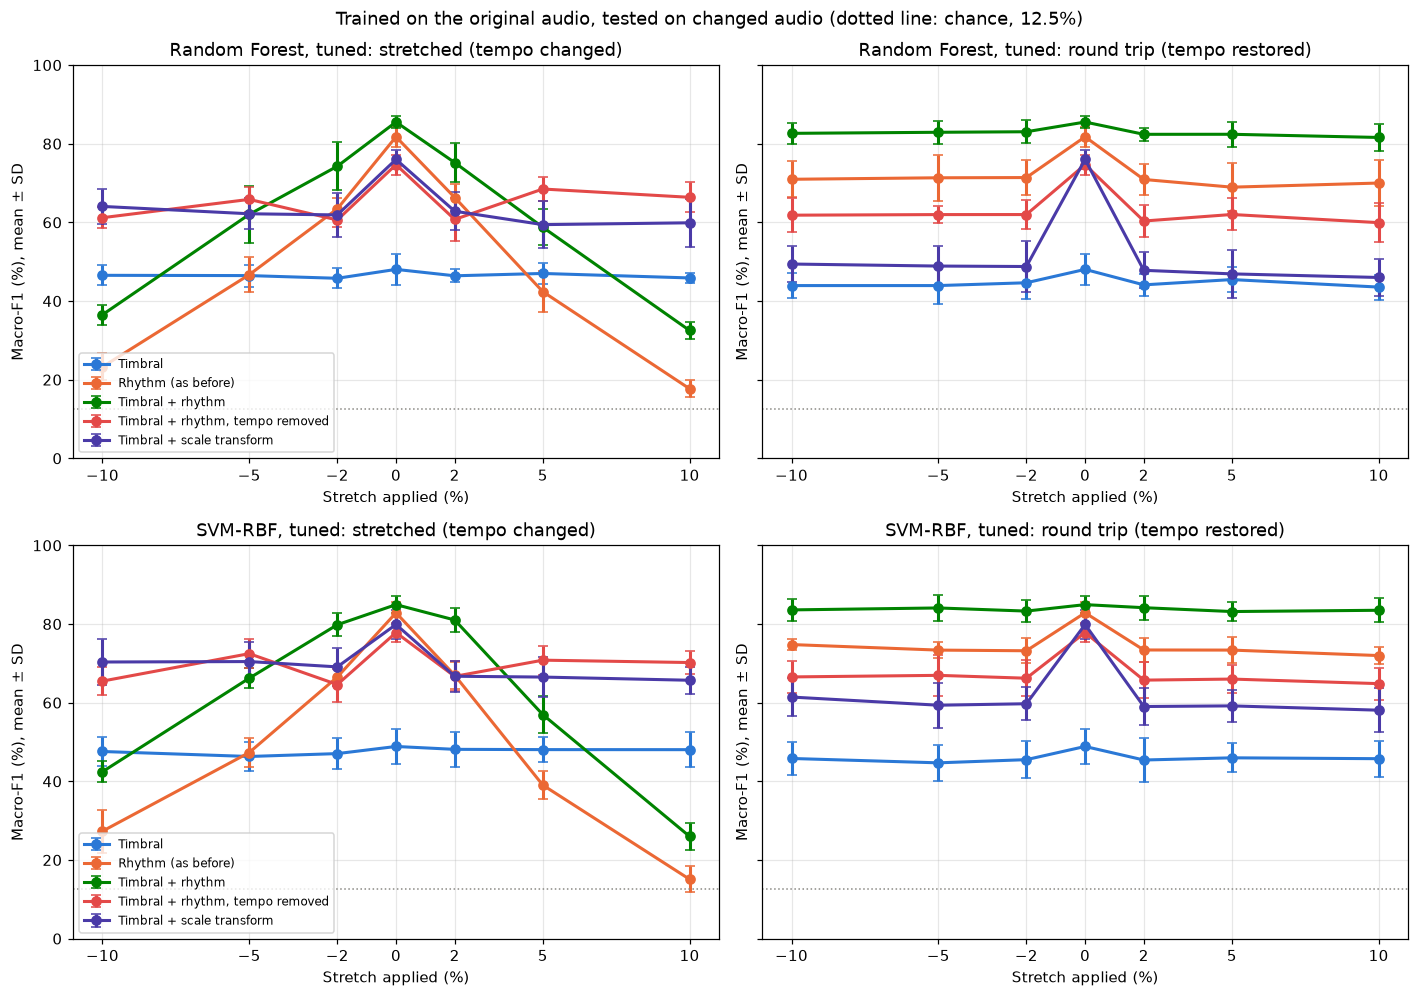

In [9]:
figure, axes = plt.subplots(len(MODEL_NAMES), 2, figsize=(13, 4.6*len(MODEL_NAMES)), sharey=True)
for row, model_name in enumerate(MODEL_NAMES):
    curves = {set_name: condition_metrics[model_name, set_name] for set_name in FEATURE_SETS}
    E.plot_robustness(curves, {name: E.SET_COLORS[name] for name in FEATURE_SETS}, model_name, axes[row])
figure.suptitle('Trained on the original audio, tested on changed audio (dotted line: chance, 12.5%)')
figure.tight_layout()
save_figure(figure, 'robustness_curves.png')

Timbre doesn't remove the tempo shortcut: timbral + rhythm still loses about 25 points because of the tempo and falls to 26-33% at +10%.

Timbral + rhythm with the tempo removed is the most robust: no drop from the tempo, and 61-73% at every stretch (66-70% at +10%), although it is 7-11 points worse on the original audio. It loses 12-13 points in the round trip, so it does react to the processing.

Timbral + scale transform doesn't react to the tempo either, but loses 20-28 points in the round trip.

## 9. How much the combined models use the timbre

We shuffle one group of features at a time and look at how much macro-F1 drops.

In [10]:
TIMBRAL_GROUPS = {'MFCC': [c for c in F.TIMBRAL_COLUMNS if c.startswith('mfcc_')],
                  'Zero-crossing rate': ['zcr_mean', 'zcr_std'],
                  'Spectral centroid': ['spectral_centroid_mean', 'spectral_centroid_std']}
RHYTHM_GROUPS = {'Bar ratios': F.RATIO_COLUMNS, 'PLP': F.PLP_COLUMNS}
GROUPS = {
    'Timbral + rhythm': {**TIMBRAL_GROUPS, 'Cyclic tempogram': F.CYCLIC_COLUMNS, **RHYTHM_GROUPS},
    'Timbral + rhythm, tempo removed': {**TIMBRAL_GROUPS, 'Shifted cyclic tempogram': F.SHIFTED_COLUMNS, **RHYTHM_GROUPS},
    'Timbral + scale transform': {**TIMBRAL_GROUPS, 'Scale transform': F.SCALE_COLUMNS},
}

rows = []
for set_name, groups in GROUPS.items():
    for model_name in MODEL_NAMES:
        importance = E.group_importance(cv[model_name, set_name], data, groups)
        for family, values in importance.iterrows():
            rows.append({'feature set': set_name, 'model': model_name, 'family': family,
                         'macro-F1 drop (pp)': 100*values['mean'], 'SD (pp)': 100*values['std']})
importance = pd.DataFrame(rows)
save(importance, 'feature_family_importance.csv', index=False)
display(importance.pivot_table(index=['feature set', 'family'], columns='model', values='macro-F1 drop (pp)',
                               sort=False).round(1))

model                                                     Random Forest  \
feature set                     family                                    
Timbral + rhythm                Cyclic tempogram                   60.5   
                                MFCC                                6.2   
                                PLP                                 3.9   
                                Spectral centroid                   2.4   
                                Bar ratios                          1.3   
                                Zero-crossing rate                 -0.2   
Timbral + rhythm, tempo removed MFCC                               13.5   
                                PLP                                16.9   
                                Spectral centroid                   2.7   
                                Bar ratios                          1.5   
                                Zero-crossing rate                  0.5   
                                Shifted cyclic tempogram           31.3   
Timbral + scale transform       MFCC                               12.6   
                                Spectral centroid                   3.4   
                                Zero-crossing rate                  0.2   
                                Scale transform                    48.1   

model                                                     SVM-RBF  
feature set                     family                             
Timbral + rhythm                Cyclic tempogram             51.2  
                                MFCC                         20.5  
                                PLP                           3.7  
                                Spectral centroid            -0.2  
                                Bar ratios                    1.2  
                                Zero-crossing rate           -0.4  
Timbral + rhythm, tempo removed MFCC                         29.6  
                                PLP                          15.4  
                                Spectral centroid             3.1  
                                Bar ratios                    3.7  
                                Zero-crossing rate            1.8  
                                Shifted cyclic tempogram     28.5  
Timbral + scale transform       MFCC                         29.6  
                                Spectral centroid             1.5  
                                Zero-crossing rate            1.3  
                                Scale transform              49.3

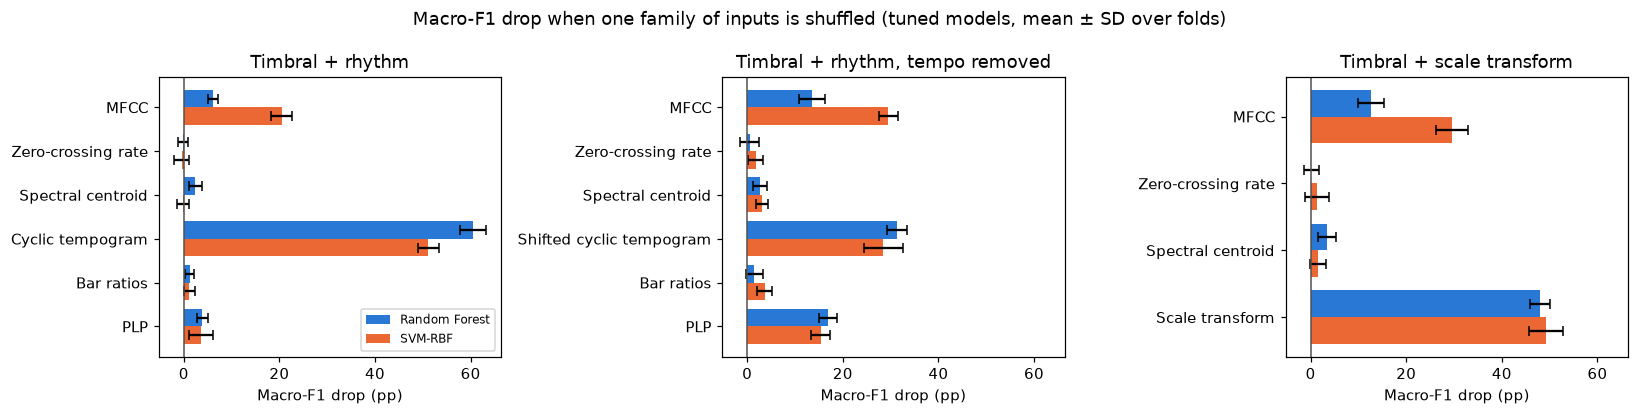

In [11]:
figure, axes = plt.subplots(1, len(GROUPS), figsize=(15, 3.8), sharex=True)
for axis, (set_name, groups) in zip(axes, GROUPS.items()):
    rows = importance[importance['feature set'] == set_name]
    families = list(groups)
    positions = np.arange(len(families))
    for offset, model_name, color in zip([-0.2, 0.2], MODEL_NAMES, [E.SET_COLORS['Timbral'], E.SET_COLORS['Rhythm (as before)']]):
        values = rows[rows['model'] == model_name].set_index('family').loc[families]
        axis.barh(positions + offset, values['macro-F1 drop (pp)'], height=0.4, xerr=values['SD (pp)'],
                  color=color, capsize=3, label=model_name)
    axis.set_yticks(positions, families)
    axis.invert_yaxis()
    axis.axvline(0, color='#52514e', linewidth=1)
    axis.set(title=set_name, xlabel='Macro-F1 drop (pp)')
axes[0].legend(loc='lower right', fontsize=8)
figure.suptitle('Macro-F1 drop when one family of inputs is shuffled (tuned models, mean ± SD over folds)')
figure.tight_layout()
save_figure(figure, 'feature_family_importance.png')

With the normal rhythm features, the cyclic tempogram matters by far the most (51-61 points) and the MFCCs much less (6 points for the Random Forest, 21 for the SVM). Without the tempo, the MFCCs matter about twice as much and share the work with the shifted tempogram.

## 10. Everything in one picture

One point per feature set (mean of the two classifiers): the score on the original audio against the average score on the six stretched versions. On the diagonal, a model loses nothing when the tempo changes.

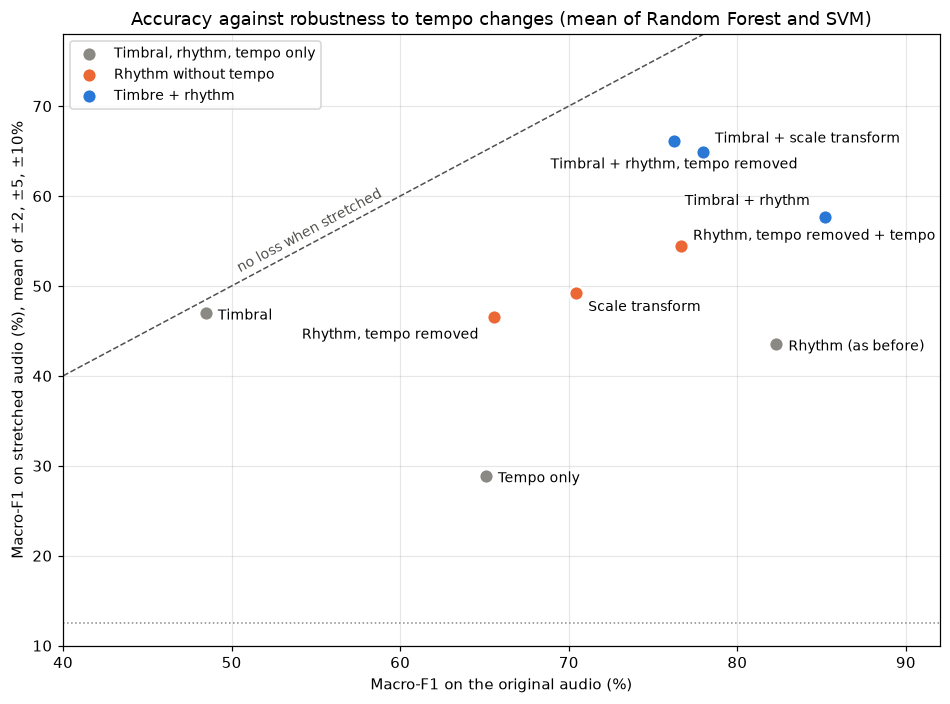

,original macro-F1 (%),stretched macro-F1 (%)
feature set,,
Rhythm (as before),82.3,43.5
Tempo only,65.1,28.8
"Rhythm, tempo removed",65.6,46.5
Scale transform,70.4,49.2
"Rhythm, tempo removed + tempo",76.6,54.5
Timbral,48.5,46.9
Timbral + rhythm,85.2,57.6
"Timbral + rhythm, tempo removed",76.3,66.1
Timbral + scale transform,77.9,64.9


In [12]:
experiment_1 = pd.read_csv('results/rhythm_without_tempo/tempo_effect.csv')
experiment_2 = pd.read_csv(RESULTS_DIR / 'tempo_effect.csv')
both = pd.concat([experiment_1, experiment_2]).drop_duplicates(['model', 'feature set'])
both['stretched macro-F1 (%)'] = both['original macro-F1 (%)'] + both['mean change, stretch (pp)']
points = both.groupby('feature set', sort=False)[['original macro-F1 (%)', 'stretched macro-F1 (%)']].mean()

GROUPS = {'Timbral, rhythm, tempo only': (['Timbral', 'Tempo only', 'Rhythm (as before)'], '#8a8984'),
          'Rhythm without tempo': (['Rhythm, tempo removed', 'Scale transform',
                                                  'Rhythm, tempo removed + tempo'], '#eb6834'),
          'Timbre + rhythm': (['Timbral + rhythm', 'Timbral + rhythm, tempo removed',
                                             'Timbral + scale transform'], '#2a78d6')}
LABEL_POSITIONS = {'Timbral': (8, -4, 'left'), 'Tempo only': (8, -4, 'left'), 'Rhythm (as before)': (8, -4, 'left'),
                   'Rhythm, tempo removed': (-10, -14, 'right'), 'Scale transform': (8, -12, 'left'),
                   'Rhythm, tempo removed + tempo': (8, 4, 'left'), 'Timbral + rhythm': (-10, 8, 'right'),
                   'Timbral + rhythm, tempo removed': (0, -18, 'center'), 'Timbral + scale transform': (8, 6, 'left')}

figure, axis = plt.subplots(figsize=(9, 6.5))
axis.plot([0, 100], [0, 100], color='#52514e', linestyle='--', linewidth=1)
axis.text(50.5, 51.5, 'no loss when stretched', rotation=45, transform_rotates_text=True,
          rotation_mode='anchor', color='#52514e', fontsize=9)
axis.axhline(12.5, color='#8a8984', linestyle=':', linewidth=1)
for group, (set_names, color) in GROUPS.items():
    part = points.loc[set_names]
    axis.scatter(part['original macro-F1 (%)'], part['stretched macro-F1 (%)'], s=90, color=color,
                 edgecolor='white', linewidth=1.5, zorder=3, label=group)
    for set_name, row in part.iterrows():
        dx, dy, alignment = LABEL_POSITIONS[set_name]
        axis.annotate(set_name, (row['original macro-F1 (%)'], row['stretched macro-F1 (%)']),
                      xytext=(dx, dy), textcoords='offset points', fontsize=9, ha=alignment)
axis.set(xlim=(40, 92), ylim=(10, 78), xlabel='Macro-F1 on the original audio (%)',
         ylabel='Macro-F1 on stretched audio (%), mean of ±2, ±5, ±10%',
         title='Accuracy against robustness to tempo changes (mean of Random Forest and SVM)')
axis.grid(alpha=0.3)
axis.legend(loc='upper left', fontsize=9)
figure.tight_layout()
figure.savefig('results/summary_tradeoff.png', bbox_inches='tight')
plt.show()
display(points.round(1))